# Issue #4: Estimating the Market-Implied Fed Path

**Goal.** Given one day's SR1 and SR3 futures prices, find the rate move the market expects at each
upcoming FOMC meeting.

Issue #3 goes **forward**: rate path → theoretical prices. Issue #4 runs it **backward**:

```
observed SR1/SR3 prices ──► search over meeting moves ──► the moves whose theoretical prices
                                     ▲                       best match the market
                                     │
                     (each guess is priced with the #3 code)
```

The output, one row per (observation date, upcoming meeting), is exactly the table that
Issue #5 (PR #15) uses to score forecast accuracy.

> **All data in this notebook is synthetic.** The real inputs come from other issues
> (see the table below). The synthetic prices are made with the same pricer the fit uses, so a
> clean fit recovers the answer almost exactly. That checks the code, not the model.

## The inputs and where the real ones come from

| Input | What it is | Real source |
|---|---|---|
| contracts | one day's SR1/SR3 settlement prices with reference periods | #1, PR #16: `settlement_curve(panel, date)` |
| meeting dates | FOMC **announcement** dates, including announced future ones | #2, PR #13 (`fomc_calendar.py`), plus future meetings |
| anchor | the policy rate in force today (target-range midpoint) | #2, PR #13 (`fomc_meetings.csv`) |
| basis | SOFR minus the policy rate, held fixed | estimated from published SOFR |
| realized SOFR | published daily SOFR, for days already known | **no issue collects it yet** |

Units: rates in percent inside the code; moves reported in basis points (bp).

In [1]:
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook lives in <repo>/notebooks, so the repository root is one level up.
REPO_ROOT = os.path.abspath("..")
sys.path.insert(0, REPO_ROOT)

from sofr_pricing import (
    contract_strip,
    fit_many,
    fit_meeting_moves,
    fixing_dates,
    effective_date,
    policy_level_on,
    step_fixings,
)
from sofr_pricing.synthetic import (
    make_synthetic_decisions,
    make_synthetic_market,
    make_synthetic_realized_sofr,
)

pd.options.display.float_format = "{:.4f}".format

## 1. Build one day of (synthetic) market data

We pretend today is **Monday, June 3, 2024**. The policy range is 5.25%-5.50% (midpoint 5.375%),
and SOFR sits 6 bp below the midpoint (basis = -0.06%).

`contract_strip` lists the contracts alive today: 13 monthly SR1 contracts and 6 quarterly SR3
contracts (including the one already in progress). The reference periods follow the same rules as
`sofr_data/contracts.py` in PR #16 (checked month by month for 2021-2030).

In [2]:
OBS = pd.Timestamp("2024-06-03")
ANCHOR = 5.375   # target-range midpoint, percent
BASIS = -0.06    # SOFR minus policy rate, percent

contracts = contract_strip(OBS, n_sr1=13, n_sr3=6)
contracts

,contract_id,root,reference_start,reference_end
0,SR1-2024-06,SR1,2024-06-01,2024-06-30
1,SR1-2024-07,SR1,2024-07-01,2024-07-31
2,SR1-2024-08,SR1,2024-08-01,2024-08-31
3,SR1-2024-09,SR1,2024-09-01,2024-09-30
4,SR1-2024-10,SR1,2024-10-01,2024-10-31
5,SR1-2024-11,SR1,2024-11-01,2024-11-30
6,SR1-2024-12,SR1,2024-12-01,2024-12-31
7,SR1-2025-01,SR1,2025-01-01,2025-01-31
8,SR1-2025-02,SR1,2025-02-01,2025-02-28
9,SR1-2025-03,SR1,2025-03-01,2025-03-31


Now we choose what the "market" expects at each meeting. These moves are the **answer** the fit
should find. The meeting dates are the real 2024-25 announcement dates; the expected moves are invented.

In [3]:
MEETINGS = pd.to_datetime([
    "2024-06-12", "2024-07-31", "2024-09-18", "2024-11-07", "2024-12-18",
    "2025-01-29", "2025-03-19", "2025-05-07", "2025-06-18", "2025-07-30",
    "2025-09-17", "2025-10-29", "2025-12-10",
])

# The market's expected move at each meeting, in bp (negative = cut). Unlisted meetings: 0.
EXPECTED_BPS = {
    "2024-06-12": -2.0, "2024-07-31": -6.0, "2024-09-18": -18.0, "2024-11-07": -12.0,
    "2024-12-18": -10.0, "2025-01-29": -8.0, "2025-03-19": -7.0,
}

market = make_synthetic_market(OBS, contracts, EXPECTED_BPS, ANCHOR, BASIS)
market[["contract_id", "root", "reference_start", "reference_end", "settlement_price"]]

,contract_id,root,reference_start,reference_end,settlement_price
0,SR1-2024-06,SR1,2024-06-01,2024-06-30,94.6970
1,SR1-2024-07,SR1,2024-07-01,2024-07-31,94.7050
2,SR1-2024-08,SR1,2024-08-01,2024-08-31,94.7650
3,SR1-2024-09,SR1,2024-09-01,2024-09-30,94.8370
4,SR1-2024-10,SR1,2024-10-01,2024-10-31,94.9450
5,SR1-2024-11,SR1,2024-11-01,2024-11-30,95.0370
6,SR1-2024-12,SR1,2024-12-01,2024-12-31,95.1069
7,SR1-2025-01,SR1,2025-01-01,2025-01-31,95.1702
8,SR1-2025-02,SR1,2025-02-01,2025-02-28,95.2450
9,SR1-2025-03,SR1,2025-03-01,2025-03-31,95.2721


## 2. Fit the meeting moves

`fit_meeting_moves` takes one day's prices and returns:

* `result.meetings`: one row per upcoming meeting, with the implied move and the cumulative change;
* `result.contracts`: market price, model price, and the residual for every contract;
* `result.diagnostics`: how well the fit worked;
* `result.sensitivities`: how each contract reacts to each meeting (Section 3).

In [4]:
result = fit_meeting_moves(OBS, market, MEETINGS, ANCHOR, BASIS)
result.meetings

/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: invalid value encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left =

,meeting_date,effective_date,implied_move_bps,implied_cum_change_bps,sensitivity
0,2024-06-12,2024-06-13,-2.0000,-2.0000,17.7331
1,2024-07-31,2024-08-01,-6.0000,-8.0000,15.5875
2,2024-09-18,2024-09-19,-18.0000,-26.0000,13.4419
3,2024-11-07,2024-11-08,-12.0000,-38.0000,11.2518
4,2024-12-18,2024-12-19,-10.0000,-48.0000,9.4480
5,2025-01-29,2025-01-30,-8.0000,-56.0000,7.6255
6,2025-03-19,2025-03-20,-7.0000,-63.0000,5.4025
7,2025-05-07,2025-05-08,-0.0000,-63.0000,3.2440
8,2025-06-18,2025-06-19,0.0000,-63.0000,1.4021
9,2025-07-30,2025-07-31,-0.0000,-63.0000,0.5345


In [5]:
result.diagnostics

{'n_contracts': 19,
 'n_meetings': 10,
 'rmse_bps': 3.018413965275239e-06,
 'max_abs_residual_bps': 7.9032218991415e-06,
 'jacobian_rank': 10,
 'condition_number': 59.6993803539723,
 'iterations': 4,
 'converged': True,
 'used_realized_fixings': False}

**Reading the output**

* Only meetings that can move at least one contract are unknowns. The Sep 17, 2025 meeting takes effect
  after the last contract (SR3 ending Sep 16, 2025), so no price can tell us anything about it.
* `implied_cum_change_bps` is the running total: by the third meeting, $-2 - 6 - 18 = -26$ bp.
* `rmse_bps` is tiny and `jacobian_rank` equals the number of meetings: every move is pinned down.

In [6]:
comparison = result.meetings[["meeting_date", "implied_move_bps", "sensitivity"]].copy()
comparison["true_move_bps"] = [EXPECTED_BPS.get(str(m.date()), 0.0) for m in comparison["meeting_date"]]
comparison["error_bps"] = comparison["implied_move_bps"] - comparison["true_move_bps"]
comparison

,meeting_date,implied_move_bps,sensitivity,true_move_bps,error_bps
0,2024-06-12,-2.0000,17.7331,-2.0000,-0.0000
1,2024-07-31,-6.0000,15.5875,-6.0000,-0.0000
2,2024-09-18,-18.0000,13.4419,-18.0000,0.0000
3,2024-11-07,-12.0000,11.2518,-12.0000,-0.0000
4,2024-12-18,-10.0000,9.4480,-10.0000,0.0000
5,2025-01-29,-8.0000,7.6255,-8.0000,-0.0000
6,2025-03-19,-7.0000,5.4025,-7.0000,0.0000
7,2025-05-07,-0.0000,3.2440,0.0000,-0.0000
8,2025-06-18,0.0000,1.4021,0.0000,0.0000
9,2025-07-30,-0.0000,0.5345,0.0000,-0.0000


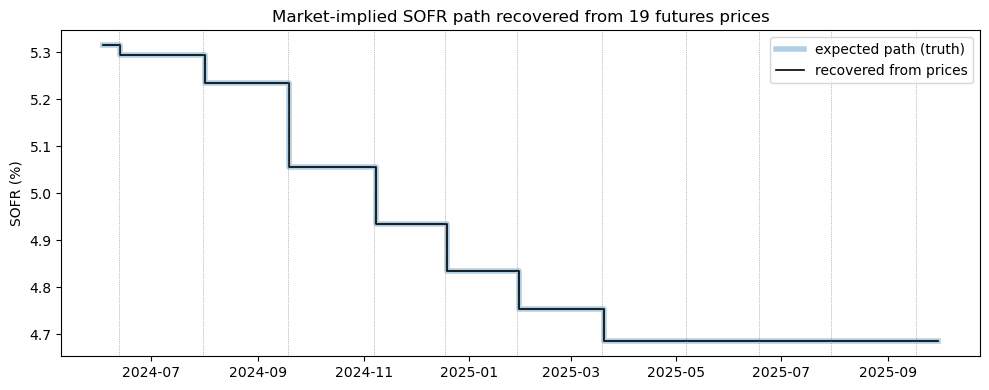

In [7]:
# Picture: the SOFR path the market expects (truth) and the one we recovered.
dates = fixing_dates("2024-06-01", "2025-09-30")

true_moves = {effective_date(m, dates): bp / 100 for m, bp in EXPECTED_BPS.items()}
fitted_moves = {row.effective_date: row.implied_move_bps / 100 for row in result.meetings.itertuples()}

true_path = step_fixings(dates, ANCHOR, true_moves, BASIS)
fitted_path = step_fixings(dates, ANCHOR, fitted_moves, BASIS)

plt.figure(figsize=(10, 4))
plt.step(true_path.index, true_path.values, where="post", linewidth=4, alpha=0.35, label="expected path (truth)")
plt.step(fitted_path.index, fitted_path.values, where="post", color="black", linewidth=1.2, label="recovered from prices")
for m in MEETINGS[MEETINGS <= "2025-09-30"]:
    plt.axvline(m, color="gray", linewidth=0.5, linestyle=":")
plt.title("Market-implied SOFR path recovered from 19 futures prices")
plt.ylabel("SOFR (%)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. What the fit "sees": the sensitivity table

How much does each contract's price move (in bp) if a meeting's rate moves by 1 bp? This table is what
the solver uses internally (the Jacobian). You can check the numbers by hand:

* The Jun 12 meeting takes effect Jun 13, which leaves 18 of June's 30 days: SR1 June moves by $-18/30 = -0.6$.
* The Jul 31 meeting takes effect Aug 1: no effect on SR1 July, and all of SR1 August ($-1.0$).

             2024-06-12  2024-07-31
SR1-2024-06     -0.6000      0.0000
SR1-2024-07     -1.0000      0.0000
SR1-2024-08     -1.0000     -1.0000


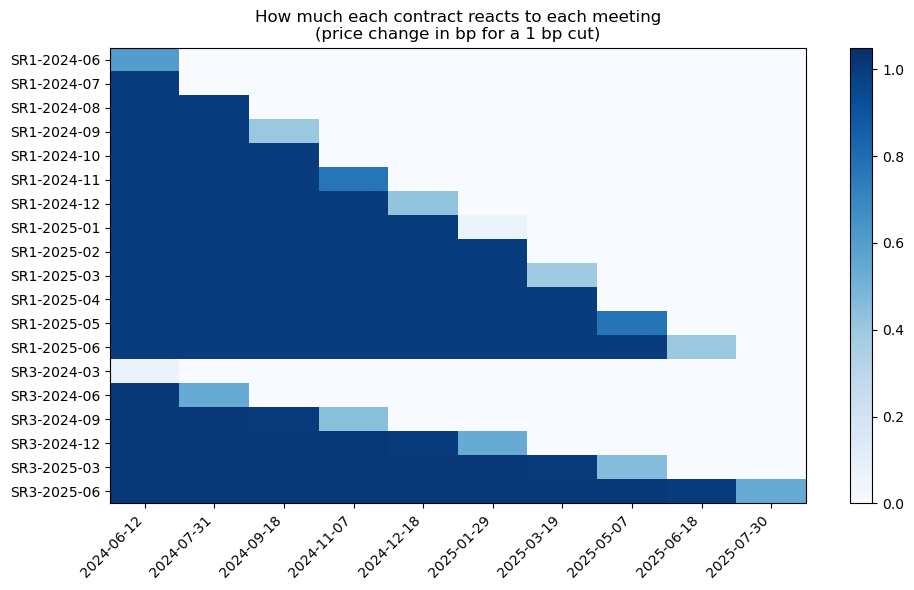

In [8]:
sens = result.sensitivities
print(sens.loc[["SR1-2024-06", "SR1-2024-07", "SR1-2024-08"], ["2024-06-12", "2024-07-31"]])

fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(-sens.values, cmap="Blues", aspect="auto", vmin=0, vmax=1.05)
ax.set_xticks(range(sens.shape[1]))
ax.set_xticklabels(sens.columns, rotation=45, ha="right")
ax.set_yticks(range(sens.shape[0]))
ax.set_yticklabels(sens.index)
ax.set_title("How much each contract reacts to each meeting\n(price change in bp for a 1 bp cut)")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

**Reading the picture** (the logic of METHODOLOGY.md, Section 6)

* An **SR1** row reacts partly to the meeting inside its own month and fully to every earlier one,
  so consecutive SR1 rows separate nearby meetings from each other.
* An **SR3** row reacts to several meetings at once, so SR3 mostly pins down the *cumulative* path,
  and it reaches further out than the SR1 strip.
* The last columns are pale: few contracts see those meetings, so they are the hardest to estimate.

## 4. Real prices are noisy and sit on a tick grid

Real settlements contain small errors and are rounded. We add 0.25 bp of random noise, round every price
to a 0.0025 grid (an illustration; check the CME specification for the real tick sizes), and repeat
with 20 different random seeds.

In [9]:
individual_errors = []
cumulative_errors = []
for seed in range(20):
    noisy = make_synthetic_market(OBS, contracts, EXPECTED_BPS, ANCHOR, BASIS,
                                  noise_bps=0.25, tick=0.0025, seed=seed)
    fit = fit_meeting_moves(OBS, noisy, MEETINGS, ANCHOR, BASIS)
    truth = np.array([EXPECTED_BPS.get(str(m.date()), 0.0) for m in fit.meetings["meeting_date"]])
    error = fit.meetings["implied_move_bps"].to_numpy() - truth
    individual_errors.append(np.abs(error))
    cumulative_errors.append(np.abs(np.cumsum(error)))

noise_table = pd.DataFrame({
    "meeting_date": result.meetings["meeting_date"],
    "sensitivity": result.meetings["sensitivity"],
    "avg |error| of the move (bp)": np.mean(individual_errors, axis=0),
    "avg |error| of the cumulative change (bp)": np.mean(cumulative_errors, axis=0),
})
noise_table

/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: invalid value encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left =

,meeting_date,sensitivity,avg |error| of the move (bp),avg |error| of the cumulative change (bp)
0,2024-06-12,17.7331,0.1882,0.1882
1,2024-07-31,15.5875,0.3006,0.1991
2,2024-09-18,13.4419,0.3201,0.2303
3,2024-11-07,11.2518,0.3559,0.1461
4,2024-12-18,9.4480,0.1798,0.1668
5,2025-01-29,7.6255,0.3032,0.1743
6,2025-03-19,5.4025,0.2863,0.2236
7,2025-05-07,3.2440,0.4039,0.2457
8,2025-06-18,1.4021,0.8668,0.6533
9,2025-07-30,0.5345,1.3773,0.7810


**Lessons**

1. Meetings that many contracts see (high sensitivity) are recovered to a fraction of a bp.
2. The last meetings, seen by few contracts, are much less precise.
3. The **cumulative** change is more stable than the individual moves through the middle of the curve,
   because errors in neighbouring meetings partly cancel. This is one reason #5 scores cumulative
   changes rather than individual moves.

## 5. The ridge penalty

The fit adds `ridge * sum(moves**2)` to the squared price errors. A larger ridge pulls poorly
identified moves toward 0 ("no change") at the cost of a slightly worse price fit. The default
(1e-6) is tiny, so it only matters for meetings the contracts barely see.

In [10]:
noisy = make_synthetic_market(OBS, contracts, EXPECTED_BPS, ANCHOR, BASIS, noise_bps=0.25, tick=0.0025, seed=0)
rows = []
for ridge in [1e-6, 1e-3, 1e-1]:
    fit = fit_meeting_moves(OBS, noisy, MEETINGS, ANCHOR, BASIS, ridge=ridge)
    moves = fit.meetings.set_index("meeting_date")["implied_move_bps"]
    rows.append({"ridge": f"{ridge:g}",
                 "move at 2024-09-18 (truth -18)": moves[pd.Timestamp("2024-09-18")],
                 "move at 2025-07-30 (truth 0)": moves[pd.Timestamp("2025-07-30")],
                 "price fit rmse (bp)": fit.diagnostics["rmse_bps"]})
pd.DataFrame(rows)

/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: invalid value encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left =

,ridge,move at 2024-09-18 (truth -18),move at 2025-07-30 (truth 0),price fit rmse (bp)
0,1e-06,-17.5544,-2.8329,0.1027
1,0.001,-17.5426,-2.7130,0.1029
2,0.1,-16.5974,-0.6515,0.2800


At 1e-6 and 1e-3 the answers barely change. At 0.1 the far meeting is pulled toward 0, but so is the
well-identified Sep 2024 move (from about -17.6 to -16.6 bp): a large ridge biases **every** estimate,
so keep it small and report the value used.

## 6. A month already in progress: why published SOFR matters

Now today is **Monday, September 23, 2024**, after a 50 bp cut announced on Sep 18 (effective Sep 19).
The September SR1 contract averages all of September, but Sep 1-18 already happened at the **old**,
higher rate. If we price those days with today's rate, September is wrong.

In [11]:
decisions = make_synthetic_decisions(["2024-06-12", "2024-07-31", "2024-09-18"], [0, 0, -50])
obs = pd.Timestamp("2024-09-23")
anchor = policy_level_on(obs, decisions, after_announcement=False)   # 4.875 after the cut
realized = make_synthetic_realized_sofr("2024-05-01", obs, decisions, basis=BASIS)

expected = {"2024-11-07": -20.0, "2024-12-18": -15.0, "2025-01-29": -10.0}
schedule = MEETINGS.append(pd.DatetimeIndex(["2026-01-28"]))
sept_market = make_synthetic_market(obs, contract_strip(obs), expected, anchor, BASIS, realized_fixings=realized)

with_realized = fit_meeting_moves(obs, sept_market, schedule, anchor, BASIS, realized_fixings=realized)
without_realized = fit_meeting_moves(obs, sept_market, schedule, anchor, BASIS)

pd.DataFrame({
    "residual with published SOFR (bp)": with_realized.contracts.set_index("contract_id")["residual_bps"],
    "residual without (bp)": without_realized.contracts.set_index("contract_id")["residual_bps"],
}).head(4)

/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: invalid value encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left =

,residual with published SOFR (bp),residual without (bp)
contract_id,,
SR1-2024-09,0.0000,-30.0000
SR1-2024-10,0.0000,0.0000
SR1-2024-11,0.0000,0.1768
SR1-2024-12,0.0000,0.1141


**Hand check.** Without published SOFR, Sep 1-18 (18 of 30 days) are priced 50 bp too low, so the
September SR1 rate is $50 \times 18/30 = 30$ bp too low and its model price 30 bp too high:
residual = market − model = **−30 bp**.

The other contracts barely change, because no unknown meeting can move September's past days. The
fit cannot hide this error; it shows up in `rmse_bps`. That is why #4 needs **published daily SOFR**,
which no issue collects yet.

## 7. Many dates at once: the table for Issue #5

`fit_many` runs the fit for every observation date and returns two tables:

* `implied`: one row per (obs_date, meeting) with `implied_move_bps` and `implied_cum_change_bps`.
  These are the column names PR #15 reads.
* `diagnostics`: one row per date.

It also handles **decision days** the way agreed in the PR #15 review: a meeting announced on the
observation date is known by settlement time, so it is applied to the path (from its effective date)
instead of being fitted, and the cumulative changes start after it.

We simulate 2024 with a market that expects **3 bp more** than the Fed delivered at every meeting.

In [12]:
meetings = pd.to_datetime([
    "2024-01-31", "2024-03-20", "2024-05-01", "2024-06-12", "2024-07-31", "2024-09-18", "2024-11-07", "2024-12-18",
    "2025-01-29", "2025-03-19", "2025-05-07", "2025-06-18", "2025-07-30", "2025-09-17", "2025-10-29", "2025-12-10",
    "2026-01-28", "2026-03-18", "2026-04-29", "2026-06-17", "2026-07-29", "2026-09-16",
])
changes = [0, 0, 0, 0, 0, -50, -25, -25,  0, 0, 0, 0, 0, -25, -25, -25,  0, 0, 0, 0, 0, 0]
history = make_synthetic_decisions(meetings, changes)

obs_dates = pd.bdate_range("2024-01-02", "2024-12-31")[::10]   # every 10th business day
frames = []
for day in obs_dates:
    day_anchor = policy_level_on(day, history, after_announcement=False)
    known = {}
    if (history["meeting_date"] == day).any():   # a decision announced today
        known = {day + pd.offsets.BDay(1): policy_level_on(day, history) - day_anchor}
    ahead = history[history["meeting_date"] > day]
    expected = {row.meeting_date: row.change_bps + 3.0 for row in ahead.itertuples()}
    one_day = make_synthetic_market(day, contract_strip(day), expected, day_anchor, BASIS, known_moves=known)
    frames.append(one_day.assign(trade_date=day))
panel = pd.concat(frames, ignore_index=True)   # same shape as #1's settlement panel

implied, diagnostics = fit_many(panel, obs_dates, history, meeting_dates=meetings, basis=BASIS)
print(f"{len(obs_dates)} dates, all converged: {diagnostics['converged'].all()}")
implied.head(8)

/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: invalid value encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left =

27 dates, all converged: True


/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: invalid value encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
  left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)
/Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
  left =

,obs_date,meeting_date,effective_date,implied_move_bps,implied_cum_change_bps
0,2024-01-02,2024-01-31,2024-02-01,3.0000,3.0000
1,2024-01-02,2024-03-20,2024-03-21,3.0000,6.0000
2,2024-01-02,2024-05-01,2024-05-02,3.0000,9.0000
3,2024-01-02,2024-06-12,2024-06-13,3.0000,12.0000
4,2024-01-02,2024-07-31,2024-08-01,3.0000,15.0000
5,2024-01-02,2024-09-18,2024-09-19,-46.9999,-32.0000
6,2024-01-02,2024-11-07,2024-11-08,-22.0000,-54.0000
7,2024-01-02,2024-12-18,2024-12-19,-22.0000,-76.0000


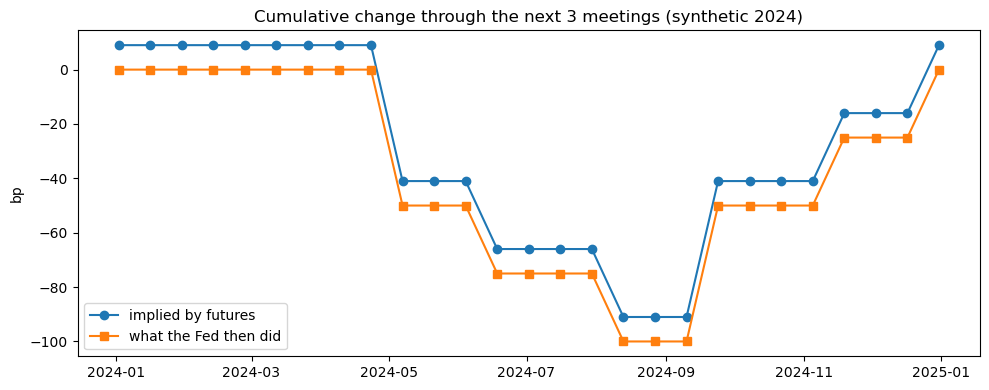

In [13]:
# Picture: implied cumulative change through the next 3 meetings, versus what the Fed then did.
three_ahead = implied.groupby("obs_date").nth(2).reset_index(drop=True)   # 3rd upcoming meeting

realized_cum = []
for row in three_ahead.itertuples():
    window = history[(history["meeting_date"] > row.obs_date) & (history["meeting_date"] <= row.meeting_date)]
    realized_cum.append(window["change_bps"].sum())

plt.figure(figsize=(10, 4))
plt.plot(three_ahead["obs_date"], three_ahead["implied_cum_change_bps"], marker="o", label="implied by futures")
plt.plot(three_ahead["obs_date"], realized_cum, marker="s", label="what the Fed then did")
plt.title("Cumulative change through the next 3 meetings (synthetic 2024)")
plt.ylabel("bp")
plt.legend()
plt.tight_layout()
plt.show()

The gap between the lines is $3 \times 3 = 9$ bp everywhere, exactly the bias we built in.

**Handing the table to #5.** Once PR #15 is merged, the evaluation is two lines. This was checked
against the PR #15 code: it recovers a bias of $3h$ bp at horizon $h$.

```python
from forecast_eval import build_forecast_errors, summarize_by_horizon

errors = build_forecast_errors(implied, history[["meeting_date", "change_bps"]])
summarize_by_horizon(errors)
```

## 8. Using the real data (once #1 and #2 are merged)

```python
import pandas as pd
from sofr_data import load_settlements                       # PR #16 (Issue #1)
from sofr_pricing import fit_many

panel = load_settlements()                                    # SR1/SR3 settlements
decisions = pd.read_csv("data/processed/fomc_meetings.csv",   # PR #13 (Issue #2)
                        parse_dates=["meeting_date"])

# The schedule must reach beyond the last contract: add announced future meetings.
future = pd.to_datetime(["2026-10-28", "2026-12-09"])         # check the Fed's calendar
meeting_dates = list(decisions["meeting_date"]) + list(future)

implied, diagnostics = fit_many(
    panel, obs_dates=sorted(panel["trade_date"].unique()),
    decisions=decisions, meeting_dates=meeting_dates,
    basis=-0.05,              # placeholder: estimate it with estimate_basis() from published SOFR
    realized_fixings=None,    # placeholder: published daily SOFR (not collected yet)
    months_ahead=18, skip_errors=True,
)
```

## 9. Limits and next steps

**Inputs we still need**

* **Published daily SOFR.** Not collected by any issue yet, but needed for the basis and for contracts
  already in progress (Section 6).
* **Future meeting dates** beyond September 2026, for the late observation dates. The fit raises an error
  if the schedule stops too early.

**Assumptions to confirm**

* Futures settle **after** the FOMC announcement on decision days, so that day's decision counts as known.
* SOFR for a day is published the next business day.
* The basis is constant over the fit horizon.

**What the numbers mean**

* The implied moves are **expectations** that may include risk premia; they are not 25 bp multiples.

**Practical**

* Speed: about 0.3 s per date, so the whole sample (about 1,200 dates) takes several minutes.

## 10. Unit tests

In [14]:
result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests", "-q", "--color=no", "-p", "no:cacheprovider"],
    cwd=REPO_ROOT, capture_output=True, text=True,
)
print(result.stdout[-1500:])

......................................................                   [100%]
=============================== warnings summary ===============================
tests/test_estimation.py: 68 warnings
  /Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: divide by zero encountered in matmul
    left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)

tests/test_estimation.py: 68 warnings
  /Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: overflow encountered in matmul
    left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)

tests/test_estimation.py: 68 warnings
  /Users/theoli/Documents/Work/UChicago/Courses/37000_futures/project/sofr_pricing/estimation.py:264: RuntimeWarning: invalid value encountered in matmul
    left = jacobian.T @ jacobian + ridge * np.eye(n_meetings)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
54 pas